## Targeting Strategies
Aims to compare the effects of targeting the top 30% of customers using various strategies
1. Causal forest targeting
2. Random targeting
3. Spend-based targeting
4. Linear interaction model targeting
5. Treat everyone

### 1. Causal Forest Targeting

Run causal_forest.ipynb notebook if haven't

Reading data from /Users/edenaong/Downloads/Y4S1/DSE4101/DSE4101-CausalForest-Grp2/data/processed/retailhero_causal_forest_features.csv
Saving output to /Users/edenaong/Downloads/Y4S1/DSE4101/DSE4101-CausalForest-Grp2/data/output
Dataset shape: (200039, 25)
Dataset columns: ['client_id', 'age', 'gender_F', 'gender_M', 'gender_U', 'num_transactions', 'num_unique_products', 'num_stores_visited', 'total_quantity', 'avg_items_per_transaction', 'total_spend', 'avg_transaction_spend', 'median_transaction_spend', 'spend_std', 'regular_points_received', 'regular_points_spent', 'express_points_received', 'express_points_spent', 'net_regular_points_change', 'net_express_points_change', 'days_since_last_purchase', 'avg_days_between_transactions', 'customer_activity_span', 'treatment', 'target']
treatment distribution: treatment
0    0.500192
1    0.499808
Name: proportion, dtype: float64
target distribution: target
1    0.619889
0    0.380111
Name: proportion, dtype: float64


,client_id,age,gender_F,gender_M,gender_U,num_transactions,num_unique_products,num_stores_visited,total_quantity,avg_items_per_transaction,...,regular_points_spent,express_points_received,express_points_spent,net_regular_points_change,net_express_points_change,days_since_last_purchase,avg_days_between_transactions,customer_activity_span,treatment,target
0,000012768d,45,0,0,1,4,46,3,54.0,13.500000,...,0.0,0.0,0.0,25.7,0.0,4,34.441906,103,0,1
1,000036f903,72,1,0,0,32,96,5,169.0,5.281250,...,0.0,60.0,0.0,54.9,60.0,1,3.515704,108,1,1
2,00010925a5,83,0,0,1,18,58,2,79.0,4.388889,...,-17.0,0.0,0.0,14.8,0.0,10,6.049572,102,1,1
3,0001f552b0,33,1,0,0,15,79,4,106.0,7.066667,...,0.0,0.0,0.0,78.9,0.0,2,8.010879,112,1,1
4,00020e7b18,73,0,0,1,18,175,4,394.0,21.888889,...,-592.0,0.0,-30.0,-305.9,-30.0,3,6.597343,112,1,1


Covariates:
 - age
 - gender_F
 - gender_M
 - num_transactions
 - num_unique_products
 - num_stores_visited
 - total_quantity
 - avg_items_per_transaction
 - total_spend
 - avg_transaction_spend
 - median_transaction_spend
 - spend_std
 - regular_points_received
 - regular_points_spent
 - express_points_received
 - express_points_spent
 - net_regular_points_change
 - net_express_points_change
 - days_since_last_purchase
 - avg_days_between_transactions
 - customer_activity_span
treatment distribution: treatment
0    0.500192
1    0.499808
Name: proportion, dtype: float64
target distribution: target
1    0.619889
0    0.380111
Name: proportion, dtype: float64
Train set shape: (140027, 21), Test set shape: (60012, 21)
Train treatment distribution: treatment
0    0.500196
1    0.499804
Name: proportion, dtype: float64
Train target distribution: target
1    0.619888
0    0.380112
Name: proportion, dtype: float64
Train and test sets have no overlapping customers, Train/test seperation verif

,treatment,target,cate_hat
count,60012.000000,60012.000000,60012.000000
mean,0.499817,0.619893,0.031621
std,0.500004,0.485417,0.029243
min,0.000000,0.000000,-0.045126
25%,0.000000,0.000000,0.013722
50%,0.000000,1.000000,0.027607
75%,1.000000,1.000000,0.044126
max,1.000000,1.000000,0.408425



Mean estimated CATE: 0.0316
Median estimated CATE: 0.0276

Positive CATE: 92.62%
Negative CATE: 7.38%
CATE results saved to /Users/edenaong/Downloads/Y4S1/DSE4101/DSE4101-CausalForest-Grp2/data/output/cf_cate_results.csv


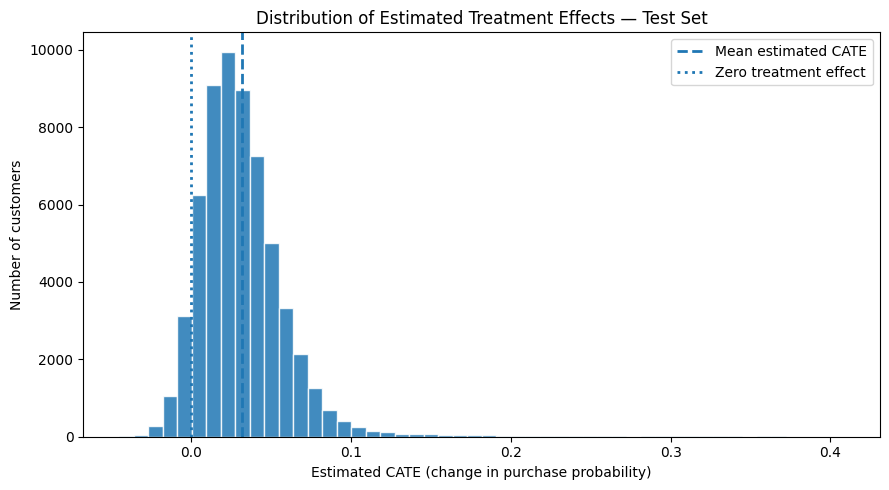

Experimental test-set ATE: 0.0332
Mean estimated CATE:      0.0316
Difference:               -0.0016
Causal forest model saved to /Users/edenaong/Downloads/Y4S1/DSE4101/DSE4101-CausalForest-Grp2/data/output/causal_forest_model.joblib
Calibration test (test set):


,estimate,std_err,t_value,p_value_one_sided
mean.forest.prediction,1.0028,0.1114,9.0052,0.0
differential.forest.prediction,0.9294,0.1241,7.4903,0.0


,bin,mean_pred_cate,observed_ate,se,n
0,0,0.0009,0.0194,0.0083,12003
1,1,0.0165,0.0206,0.0084,12002
2,2,0.0277,0.0185,0.0088,12002
3,3,0.0405,0.0297,0.0090,12002
4,4,0.0724,0.0755,0.0091,12003


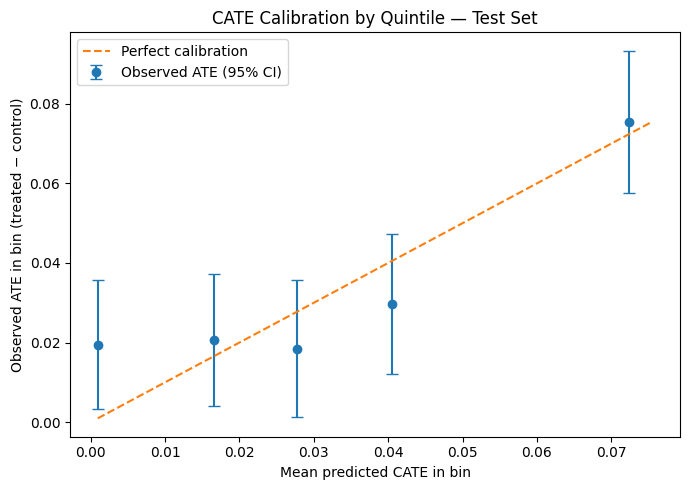

In [45]:
%run causal_forest.ipynb

Imports and settings

In [46]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

RANDOM_STATE = 1213  # must match causal_forest.ipynb so the split is identical
BUDGET = 0.30  # share of customers the firm can target
N_BOOT = 500  # number of bootstrap replications

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_PATH = next(p for p in [PROJECT_ROOT / "data" / "processed" / "retailhero_causal_forest_features.csv",
                             PROJECT_ROOT / "data" / "Processed" / "retailhero_causal_forest_features.csv"] if p.exists())
OUTPUT_DIR = PROJECT_ROOT / "data" / "output"
CATE_PATH = OUTPUT_DIR / "cf_cate_results.csv"

rng = np.random.default_rng(RANDOM_STATE)

Load data and rebuilt train / test set

In [47]:
df = pd.read_csv(DATA_PATH)
cate_results = pd.read_csv(CATE_PATH)

Y = df["target"].astype(int)
Z = df["treatment"].astype(int)
X = df.drop(columns=["target", "treatment", "client_id", "gender_U"], errors="ignore")

strata = Z.astype(str) + "_" + Y.astype(str)
X_train, X_test, Y_train, Y_test, Z_train, Z_test = train_test_split(
    X, Y, Z, test_size=0.3, random_state=RANDOM_STATE, stratify=strata)

# Check the rebuilt test set is the same customers, in the same order, as cf_cate_results.csv
test_ids = df.loc[X_test.index, "client_id"].to_numpy()
assert (test_ids == cate_results["client_id"].to_numpy()).all(), \
    "Test set does not match cf_cate_results.csv - rerun causal_forest.ipynb"
print(f"Test set verified: {len(test_ids):,} customers")

tau_hat = cate_results["cate_hat"].to_numpy()
y_te, z_te = Y_test.to_numpy(), Z_test.to_numpy()
n = len(y_te)

Test set verified: 60,012 customers


AIPW (Augmented Inverse Probability Weighting) score for RATE (Rank Average Treatment Effect)

In [48]:
def fit_mu(arm):
    m = RandomForestRegressor(n_estimators=100, min_samples_leaf=50,
                              random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train[Z_train == arm], Y_train[Z_train == arm])
    return m.predict(X_test)

mu1, mu0 = fit_mu(1), fit_mu(0)
e = Z_train.mean()

gamma = (mu1 - mu0
         + z_te * (y_te - mu1) / e
         - (1 - z_te) * (y_te - mu0) / (1 - e))

ate = gamma.mean()
dim = y_te[z_te == 1].mean() - y_te[z_te == 0].mean()
print(f"ATE (AIPW):               {ate:.4f}")
print(f"ATE (difference in means): {dim:.4f}   <- should be very close")

ATE (AIPW):               0.0315
ATE (difference in means): 0.0332   <- should be very close


Rank customers by CATE and select top 30%

In [49]:
def rank_order(score, rng):
    """Indices sorted from highest to lowest score; ties broken at random."""
    return np.lexsort((rng.random(len(score)), -score))

k = int(round(BUDGET * n))
order = rank_order(tau_hat, rng)

ranked = cate_results.copy()
ranked["gamma"] = gamma
ranked["cf_rank"] = np.empty(n, dtype=int)
ranked.loc[order, "cf_rank"] = np.arange(1, n + 1)
ranked["cf_top30"] = ranked["cf_rank"] <= k
ranked = ranked.sort_values("cf_rank")
display(ranked.head(10))

top = order[:k]
t, c = z_te[top] == 1, z_te[top] == 0
print(f"Customers targeted:                        {k:,}")
print(f"Uplift per targeted customer (AIPW):       {gamma[top].mean():.4f}")
print(f"Uplift per targeted customer (diff. means): {y_te[top][t].mean() - y_te[top][c].mean():.4f}")
print(f"Incremental purchases (test set):          {gamma[top].sum():.1f}")

ranked.to_csv(OUTPUT_DIR / "cf_ranked_customers.csv", index=False)

,client_id,treatment,target,cate_hat,gamma,cf_rank,cf_top30
983,205a845a5b,0,0,0.408425,0.802524,1,True
4245,5c270e445b,1,1,0.403882,1.341736,2,True
24829,f0ecaaaf57,1,1,0.401735,1.382936,3,True
34826,eb7881a604,1,1,0.398252,1.290167,4,True
7380,56b9d0d410,0,0,0.391964,0.934066,5,True
4411,ff47ffe826,1,1,0.390174,1.386189,6,True
30594,ff793eeb4b,1,0,0.379792,-0.852751,7,True
5064,55ef8029e8,1,1,0.378612,1.046007,8,True
32984,96b5100a11,0,1,0.376278,-1.231750,9,True
29584,7ec9fedd4b,1,0,0.371336,-0.855970,10,True


Customers targeted:                        18,004
Uplift per targeted customer (AIPW):       0.0586
Uplift per targeted customer (diff. means): 0.0610
Incremental purchases (test set):          1055.3


Qini curve and AUQ

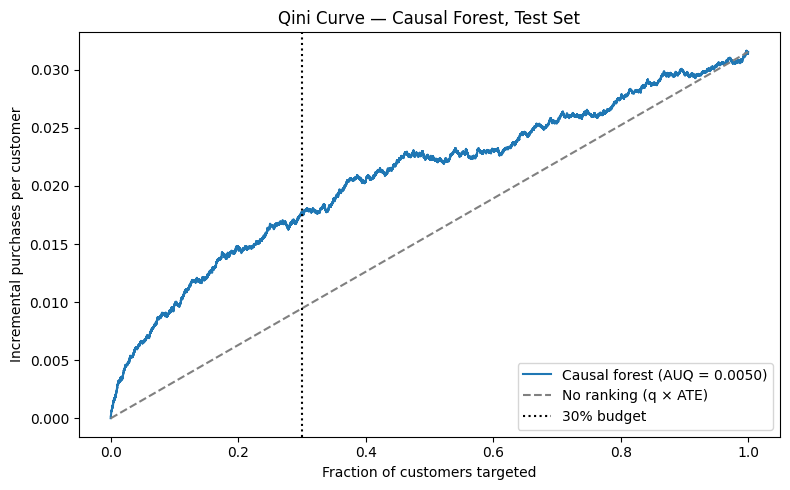

In [50]:
def qini_curve(score, gamma, rng):
    m = len(gamma)
    q = np.arange(1, m + 1) / m
    Q = np.cumsum(gamma[rank_order(score, rng)]) / m
    return q, Q

def auq(score, gamma, rng):
    q, Q = qini_curve(score, gamma, rng)
    return np.mean(Q - q * gamma.mean())

def value_at(score, gamma, rng, budget=BUDGET):
    """Q(budget): incremental purchases per customer in the population at the cutoff."""
    m = len(gamma)
    return gamma[rank_order(score, rng)[:int(round(budget * m))]].sum() / m

q, Q = qini_curve(tau_hat, gamma, rng)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(q, Q, label=f"Causal forest (AUQ = {auq(tau_hat, gamma, rng):.4f})")
ax.plot([0, 1], [0, ate], linestyle="--", color="grey", label="No ranking (q × ATE)")
ax.axvline(BUDGET, linestyle=":", color="black", label=f"{BUDGET:.0%} budget")
ax.set_xlabel("Fraction of customers targeted")
ax.set_ylabel("Incremental purchases per customer")
ax.set_title("Qini Curve — Causal Forest, Test Set")
ax.legend()
plt.tight_layout()
plt.show()

Bootstrap for standard error and confidence intervals

In [51]:
def stats_on(idx, rng):
    g, s = gamma[idx], tau_hat[idx]
    return {
        "ATE": g.mean(),
        "AUQ (Qini coefficient)": auq(s, g, rng),
        "Q(30%)": value_at(s, g, rng),
        "Uplift per targeted customer": value_at(s, g, rng) / BUDGET,
    }

point = stats_on(np.arange(n), rng)
boot = pd.DataFrame([stats_on(rng.integers(0, n, n), rng) for _ in range(N_BOOT)])

results = pd.DataFrame({
    "estimate": pd.Series(point),
    "boot_se": boot.std(ddof=1),
    "ci_lower": boot.quantile(0.025),
    "ci_upper": boot.quantile(0.975),
})
results["z"] = results["estimate"] / results["boot_se"]
display(results.round(4))

results.to_csv(OUTPUT_DIR / "cf_targeting_results.csv")
print(f"Saved to {OUTPUT_DIR / 'cf_targeting_results.csv'}")

,estimate,boot_se,ci_lower,ci_upper,z
ATE,0.0315,0.0034,0.0254,0.0383,9.1988
AUQ (Qini coefficient),0.0050,0.0010,0.0030,0.0069,4.9085
Q(30%),0.0176,0.0020,0.0137,0.0214,8.8514
Uplift per targeted customer,0.0586,0.0066,0.0455,0.0712,8.8514


Saved to /Users/edenaong/Downloads/Y4S1/DSE4101/DSE4101-CausalForest-Grp2/data/output/cf_targeting_results.csv


### 4. Linear Interaction Model Targeting

In [52]:
# Choosing the covariates
moderators = [
    "age",
    "total_spend",
    "num_transactions",
    "days_since_last_purchase",
    "customer_activity_span"
]

# Checking correlation
corr = X_train[moderators].corr()
display(corr.round(2))

,age,total_spend,num_transactions,days_since_last_purchase,customer_activity_span
age,1.00,-0.03,0.04,-0.04,0.10
total_spend,-0.03,1.00,0.58,-0.29,0.35
num_transactions,0.04,0.58,1.00,-0.41,0.45
days_since_last_purchase,-0.04,-0.29,-0.41,1.00,-0.34
customer_activity_span,0.10,0.35,0.45,-0.34,1.00


Standardising moderators

In [53]:
scaler = StandardScaler()

X_train_lpm = X_train[moderators].copy()
X_test_lpm = X_test[moderators].copy()

X_train_lpm[moderators] = scaler.fit_transform(X_train_lpm[moderators])
X_test_lpm[moderators] = scaler.transform(X_test_lpm[moderators])

Model Equation:

$$
\begin{aligned}
Y_i =\;& \beta_0 + \beta_D D_i
+ \beta_1 Age_i
+ \beta_2 Spend_i
+ \beta_3 Transactions_i \\
&+ \beta_4 Recency_i
+ \beta_5 ActivitySpan_i \\
&+ \gamma_1(D_i \times Age_i)
+ \gamma_2(D_i \times Spend_i) \\
&+ \gamma_3(D_i \times Transactions_i)
+ \gamma_4(D_i \times Recency_i) \\
&+ \gamma_5(D_i \times ActivitySpan_i)
+ \varepsilon_i
\end{aligned}
$$

In [54]:
train_lpm = X_train_lpm.copy()
train_lpm["treatment"] = Z_train.to_numpy()
train_lpm["target"] = Y_train.to_numpy()

formula = (
    "target ~ treatment * ("
    "age + total_spend + num_transactions + "
    "days_since_last_purchase + customer_activity_span)"
)

lpm = smf.ols(formula, data=train_lpm).fit(cov_type="HC3")

print(lpm.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.171
Model:                            OLS   Adj. R-squared:                  0.170
Method:                 Least Squares   F-statistic:                     2932.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:05   Log-Likelihood:                -84395.
No. Observations:              140027   AIC:                         1.688e+05
Df Residuals:                  140015   BIC:                         1.689e+05
Df Model:                          11                                         
Covariance Type:                  HC3                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Inte

Predict test-set CATEs

In [55]:
test_treated = X_test_lpm.copy()
test_treated["treatment"] = 1

test_control = X_test_lpm.copy()
test_control["treatment"] = 0

cate_lpm = (lpm.predict(test_treated)- lpm.predict(test_control)).to_numpy()

print("Number of predictions:", len(cate_lpm))
print("Minimum CATE:", cate_lpm.min())
print("Maximum CATE:", cate_lpm.max())
print("Average CATE:", cate_lpm.mean())

Number of predictions: 60012
Minimum CATE: -0.14123260465760312
Maximum CATE: 0.081392195514362
Average CATE: 0.03188136616597581


Rank customers by CATE and select the top 30%

In [56]:
order_lpm = rank_order(cate_lpm, np.random.default_rng(RANDOM_STATE))
top_lpm = order_lpm[:k]

print("Customers targeted:", len(top_lpm))

Customers targeted: 18004


Evaluate incremental purchases

In [57]:
uplift_lpm = gamma[top_lpm].mean()
incremental_lpm = gamma[top_lpm].sum()

print(f"LPM uplift per targeted customer: {uplift_lpm:.4f}")
print(f"LPM incremental purchases: {incremental_lpm:.1f}")

LPM uplift per targeted customer: 0.0621
LPM incremental purchases: 1117.2


Qini and AUQ

In [58]:
q_lpm, Q_lpm = qini_curve(
    cate_lpm, gamma, np.random.default_rng(RANDOM_STATE)
)

auq_lpm = auq(
    cate_lpm, gamma, np.random.default_rng(RANDOM_STATE)
)

print(f"LPM AUQ: {auq_lpm:.4f}")

LPM AUQ: 0.0060


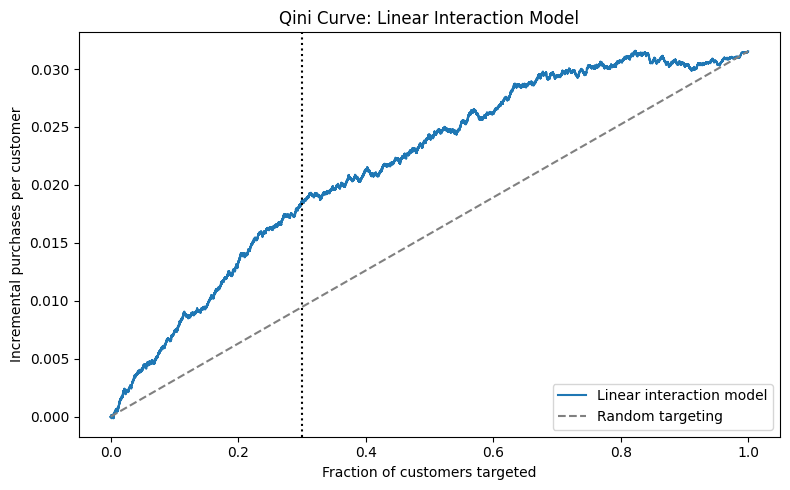

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(q_lpm, Q_lpm, label="Linear interaction model")
plt.plot([0, 1], [0, ate], "--", color="grey", label="Random targeting")

plt.axvline(0.30, linestyle=":", color="black")

plt.xlabel("Fraction of customers targeted")
plt.ylabel("Incremental purchases per customer")
plt.title("Qini Curve: Linear Interaction Model")
plt.legend()
plt.tight_layout()
plt.show()

Bootstrap

In [60]:
rng_boot = np.random.default_rng(RANDOM_STATE)

# Check that arrays are aligned
assert len(cate_lpm) == len(tau_hat) == len(gamma) == n

def stats_cf_vs_lpm(idx, rng):
    g = gamma[idx]
    cf = tau_hat[idx]
    lp = cate_lpm[idx]

    return {
        "AUQ difference (CF - LPM)": auq(cf, g, rng) - auq(lp, g, rng),
        "Q(30%) difference (CF - LPM)": value_at(cf, g, rng) - value_at(lp, g, rng),
        "Uplift per targeted customer difference": (
            value_at(cf, g, rng) - value_at(lp, g, rng)
        ) / BUDGET
    }

# Point estimates
point = stats_cf_vs_lpm(np.arange(n), rng_boot)

# Bootstrap
boot = pd.DataFrame([
    stats_cf_vs_lpm(rng_boot.integers(0, n, n), rng_boot)
    for _ in range(N_BOOT)
])

# Results table
results_lpm_comparison = pd.DataFrame({
    "estimate": pd.Series(point),
    "boot_se": boot.std(ddof=1),
    "ci_lower": boot.quantile(0.025),
    "ci_upper": boot.quantile(0.975),
})

results_lpm_comparison["z"] = (
    results_lpm_comparison["estimate"] /
    results_lpm_comparison["boot_se"]
)

display(results_lpm_comparison.round(4))

# Save results
results_lpm_comparison.to_csv(
    OUTPUT_DIR / "cf_vs_lpm_targeting_results.csv"
)
print(f"Saved to {OUTPUT_DIR / 'cf_vs_lpm_targeting_results.csv'}")

,estimate,boot_se,ci_lower,ci_upper,z
AUQ difference (CF - LPM),-0.0009,0.0012,-0.0031,0.0012,-0.8069
Q(30%) difference (CF - LPM),-0.0010,0.0021,-0.0048,0.0031,-0.5016
Uplift per targeted customer difference,-0.0034,0.0069,-0.0162,0.0103,-0.5016


Saved to /Users/edenaong/Downloads/Y4S1/DSE4101/DSE4101-CausalForest-Grp2/data/output/cf_vs_lpm_targeting_results.csv


### 5. Treating Everyone

In [61]:
everyone_summary = pd.Series({
    "Customers targeted": n,
    "Uplift per targeted customer (AIPW)": gamma.mean(),
    "Uplift per targeted customer (diff. means)": y_te[z_te == 1].mean() - y_te[z_te == 0].mean(),
    "Incremental purchases (test set)": gamma.sum(),
})
display(everyone_summary.round(4))

Customers targeted                            60012.0000
Uplift per targeted customer (AIPW)               0.0315
Uplift per targeted customer (diff. means)        0.0332
Incremental purchases (test set)               1891.8914
dtype: float64

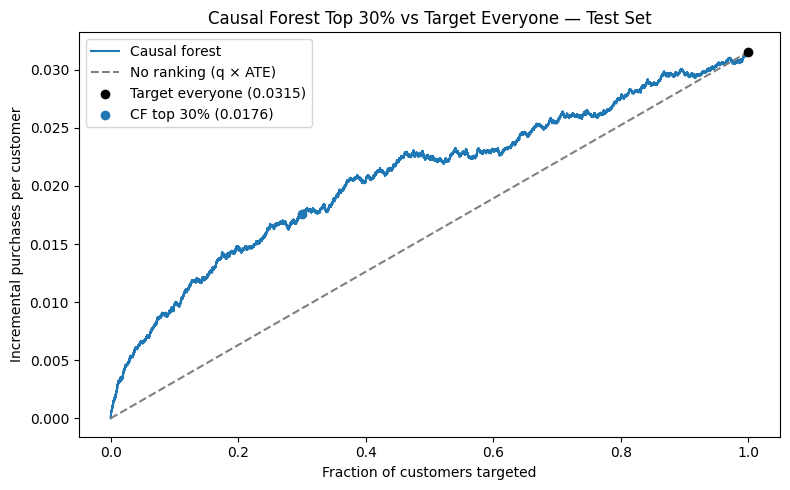

In [62]:
fig, ax = plt.subplots(figsize=(8, 5))
q, Q = qini_curve(tau_hat, gamma, rng)
ax.plot(q, Q, label="Causal forest")
ax.plot([0, 1], [0, ate], linestyle="--", color="grey", label="No ranking (q × ATE)")
ax.scatter([1], [ate], color="black", zorder=3, label=f"Target everyone ({ate:.4f})")
ax.scatter([BUDGET], [value_at(tau_hat, gamma, rng)], color="tab:blue", zorder=3,
           label=f"CF top {BUDGET:.0%} ({value_at(tau_hat, gamma, rng):.4f})")
ax.set_xlabel("Fraction of customers targeted")
ax.set_ylabel("Incremental purchases per customer")
ax.set_title("Causal Forest Top 30% vs Target Everyone — Test Set")
ax.legend()
plt.tight_layout()
plt.show()

Bootstrap

In [63]:
def stats_everyone(idx, rng):
    g, s = gamma[idx], tau_hat[idx]
    ate_b = g.mean()
    q30 = value_at(s, g, rng)
    return {
        "Everyone: uplift per targeted customer (= ATE)": ate_b,
        "Everyone: Q(100%)": ate_b,
        "CF: uplift per targeted customer": q30 / BUDGET,
        "Uplift per targeted: CF - everyone": q30 / BUDGET - ate_b,
        "Share of total uplift captured by CF top 30%": q30 / ate_b,
    }

point_ev = stats_everyone(np.arange(n), rng)
boot_ev = pd.DataFrame([stats_everyone(rng.integers(0, n, n), rng) for _ in range(N_BOOT)])

results_everyone = pd.DataFrame({
    "estimate": pd.Series(point_ev),
    "boot_se": boot_ev.std(ddof=1),
    "ci_lower": boot_ev.quantile(0.025),
    "ci_upper": boot_ev.quantile(0.975),
})
results_everyone["z"] = results_everyone["estimate"] / results_everyone["boot_se"]
display(results_everyone.round(4))

results_everyone.to_csv(OUTPUT_DIR / "everyone_targeting_results.csv")
print(f"Saved to {OUTPUT_DIR / 'everyone_targeting_results.csv'}")

,estimate,boot_se,ci_lower,ci_upper,z
Everyone: uplift per targeted customer (= ATE),0.0315,0.0034,0.0246,0.0379,9.2962
Everyone: Q(100%),0.0315,0.0034,0.0246,0.0379,9.2962
CF: uplift per targeted customer,0.0586,0.0070,0.0445,0.0727,8.4001
Uplift per targeted: CF - everyone,0.0271,0.0056,0.0173,0.0392,4.8319
Share of total uplift captured by CF top 30%,0.5578,0.0587,0.4647,0.6836,9.5097


Saved to /Users/edenaong/Downloads/Y4S1/DSE4101/DSE4101-CausalForest-Grp2/data/output/everyone_targeting_results.csv
